# 🌸 Phenikaa-Flora: 10-Class Flower Detection & xAI Training Pipeline
**Phenikaa University - Computer Vision Project**

**Mục tiêu**: Huấn luyện mô hình YOLOv8 trên GPU NVIDIA T4 Google Colab, đánh giá toàn diện, phân tích giải thích mô hình với **xAI (Grad-CAM++, Feature Maps, t-SNE)** và export sang **ONNX** để triển khai Web Realtime trên GitHub Pages.

## ⚙️ Bước 0: Kiểm tra GPU & Cài đặt thư viện cần thiết

In [1]:
# Kiểm tra GPU được cấp phát (NVIDIA T4)
!nvidia-smi

# Cài đặt Ultralytics YOLO, ONNX, và các thư viện xAI/Viz
!pip install -q ultralytics onnx onnxruntime scikit-learn matplotlib seaborn opencv-python-headless

Mon Oct 12 17:32:10 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   39C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 📦 Bước 1: Giải nén Dataset Phenikaa-FL (chuẩn YOLO)
**Lưu ý quan trọng khi tải file lên Colab:**
* **Cách 1 (Khuyên dùng - Nhanh & Ổn định nhất):** Tải file `Phenikaa-FL-YOLO.zip` lên **Google Drive** của bạn, sau đó mount Drive vào Colab. Cách này chỉ mất 2 giây, không bao giờ bị lỗi đứt mạng.
* **Cách 2 (Kéo thả trực tiếp):** Kéo thả `Phenikaa-FL-YOLO.zip` vào thư mục `/content/`. **LƯU Ý:** File nặng ~438 MB, hãy đợi **vòng tròn tiến trình màu cam/xanh ở góc dưới bên trái hoàn tất 100%** (biến mất) rồi mới chạy cell giải nén!

In [2]:
import os, zipfile, yaml, time

# Tùy chọn 1: Nếu file ở Google Drive, bỏ comment 2 dòng dưới để mount:
# from google.colab import drive
# drive.mount('/content/drive')

zip_path = '/content/Phenikaa-FL-YOLO.zip'
drive_zip = '/content/drive/MyDrive/Phenikaa-FL-YOLO.zip'

if not os.path.exists(zip_path) and os.path.exists(drive_zip):
    print(f'Tìm thấy file trong Google Drive, đang sao chép sang /content/... ({drive_zip})')
    !cp /content/drive/MyDrive/Phenikaa-FL-YOLO.zip /content/
    zip_path = '/content/Phenikaa-FL-YOLO.zip'

# Kiểm tra sự tồn tại của file
if not os.path.exists(zip_path):
    raise FileNotFoundError(
        '❌ Chưa tìm thấy file Phenikaa-FL-YOLO.zip trong /content/!\n'\
        '👉 Vui lòng kéo thả file Phenikaa-FL-YOLO.zip vào cột Files bên trái màn hình Colab,\n'\
        '   và ĐỢI vòng tròn tải lên quay xong 100% trước khi chạy cell này.'
    )

# Kiểm tra kích thước file để phát hiện trường hợp upload chưa xong
file_size = os.path.getsize(zip_path)
size_mb = file_size / (1024 * 1024)
print(f'📁 File zip hiện tại: {size_mb:.2f} MB')

EXPECTED_MIN_MB = 400.0  # File đầy đủ là ~438 MB
if size_mb < EXPECTED_MIN_MB:
    raise ValueError(
        f'⚠️ FILE CHƯA TẢI LÊN XONG!\n'\
        f'Kích thước hiện tại chỉ mới đạt {size_mb:.2f} MB / 438 MB.\n'\
        f'👉 Hãy quan sát vòng tròn tròn nhỏ xoay cạnh tên file ở thanh Files bên trái Colab.\n'\
        f'   Đợi nó chạy đầy và biến mất hoàn toàn rồi bấm chạy lại cell này nhé!'
    )

print('✅ Kích thước file hợp lệ! Đang giải nén dataset...')
!unzip -q -o /content/Phenikaa-FL-YOLO.zip -d /content/

# Cập nhật đường dẫn tuyệt đối trong data.yaml trên Colab
yaml_path = '/content/dataset_yolo/data.yaml'
with open(yaml_path, 'r') as f:
    data_cfg = yaml.safe_load(f)

data_cfg['path'] = '/content/dataset_yolo'
with open(yaml_path, 'w') as f:
    yaml.dump(data_cfg, f)

print('🎉 Giải nén thành công! Nội dung data.yaml:')
with open(yaml_path) as f:
    print(f.read())

📁 File zip hiện tại: 438.36 MB
✅ Kích thước file hợp lệ! Đang giải nén dataset...
🎉 Giải nén thành công! Nội dung data.yaml:
names:
  0: hoa_chieu_tim
  1: hoa_dam_but
  2: hoa_dam_but_cam
  3: hoa_hong
  4: hoa_lai_tay
  5: hoa_mau_don_ta
  6: hoa_mia_do
  7: hoa_mo_ket
  8: hoa_mo_trang
  9: huynh_anh_vang
nc: 10
path: /content/dataset_yolo
test: images/test
train: images/train
val: images/val



## 🚀 Bước 2: Huấn luyện mô hình YOLOv8n trên GPU T4
Sử dụng pre-trained weights `yolov8n.pt`, áp dụng tối ưu hóa AdamW, cosine annealing scheduler và data augmentation (Mosaic, Flips, Color jitter).

In [3]:
from ultralytics import YOLO

# Khởi tạo mô hình YOLOv8n
model = YOLO('yolov8n.pt')

# Bắt đầu huấn luyện
results = model.train(
    data='/content/dataset_yolo/data.yaml',
    epochs=60,
    imgsz=640,
    batch=16,
    patience=15,
    optimizer='AdamW',
    lr0=0.001,
    weight_decay=0.0005,
    device=0, # GPU T4
    project='phenikaa_flora_yolo',
    name='train_run',
    save=True,
    verbose=True
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset_yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.

## 📊 Bước 3: Đánh giá mô hình trên tập Test (Kiểm thử khách quan)
Đánh giá độ chính xác (mAP@50, mAP@50-95, Precision, Recall) và hiển thị ma trận nhầm lẫn (Confusion Matrix).

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,134,894 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4032.5±372.8 MB/s, size: 564.9 KB)
val: Scanning /content/dataset_yolo/labels/test... 88 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 88/88 1.8Kit/s 0.0s
val: New cache created: /content/dataset_yolo/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 1.3it/s 4.7s
                   all         88        157      0.907      0.904      0.925      0.805
         hoa_chieu_tim          8          8      0.964          1      0.995      0.995
           hoa_dam_but          8          8      0.961          1      0.995      0.995
       hoa_dam_but_cam         10         10      0.976          1      0.995       0.91
              hoa_hong          7          8      0.881      0.875      0.875   

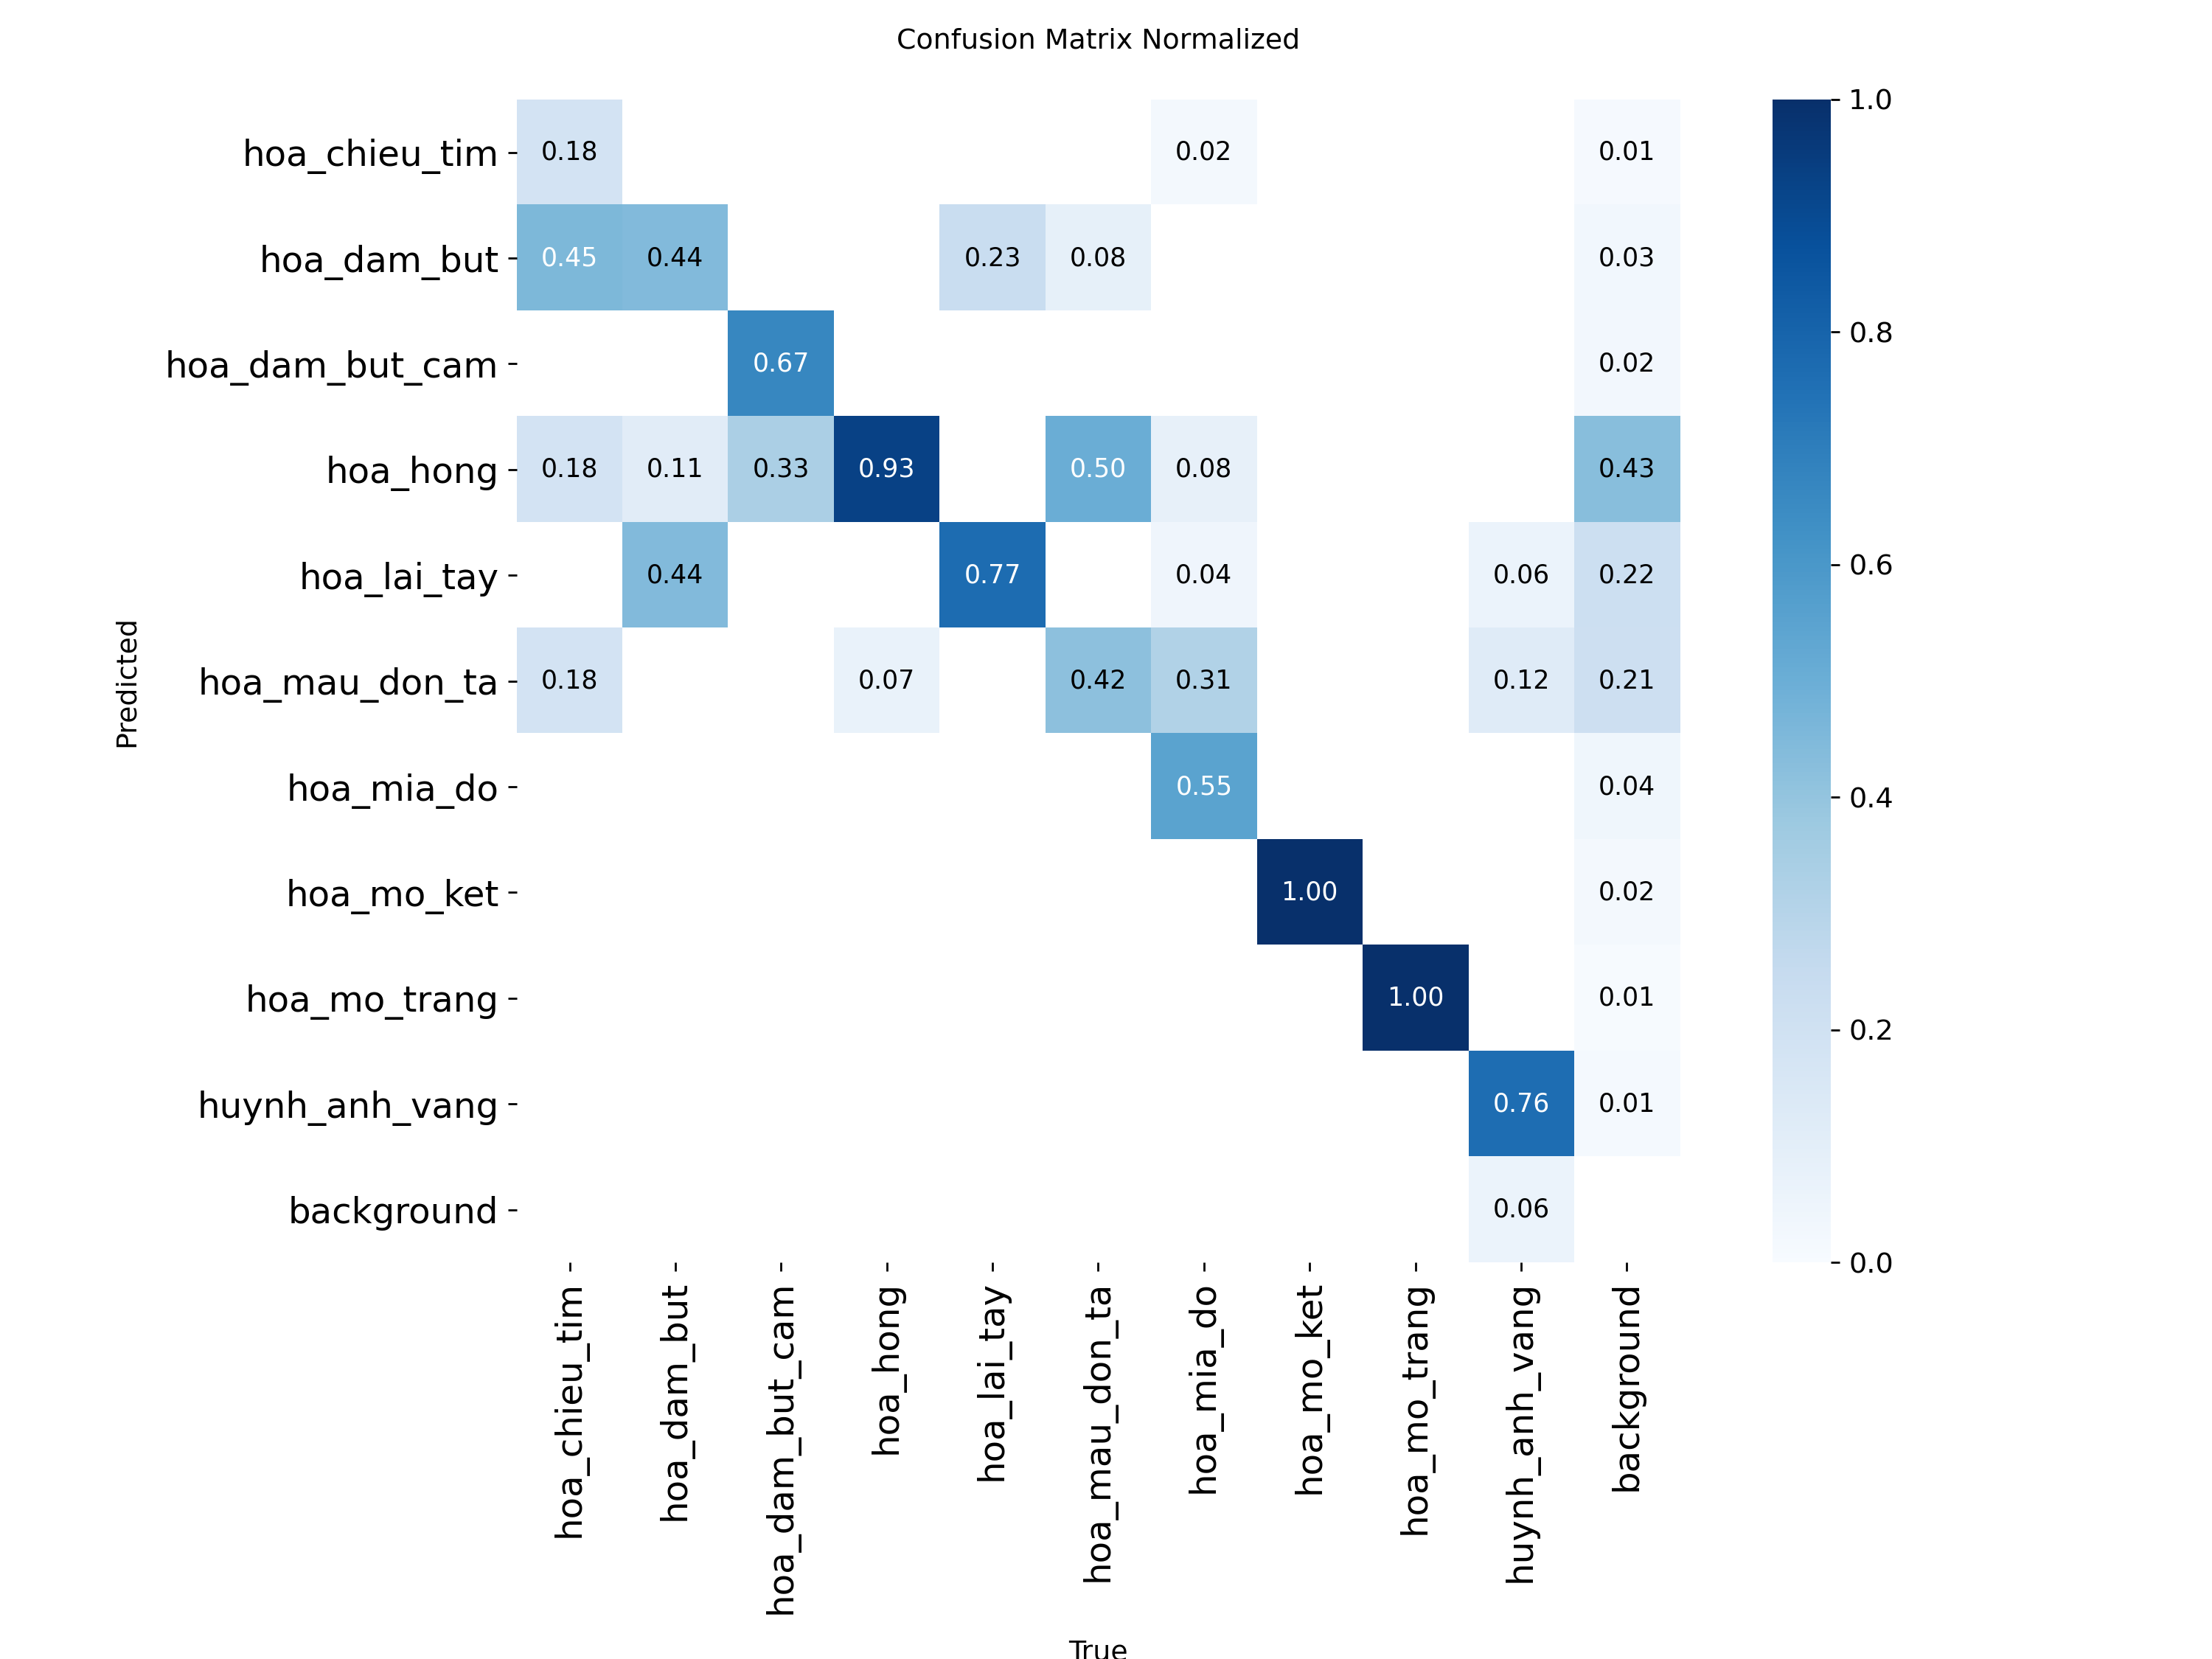


Đồ thị huấn luyện (Training & Validation Curves):


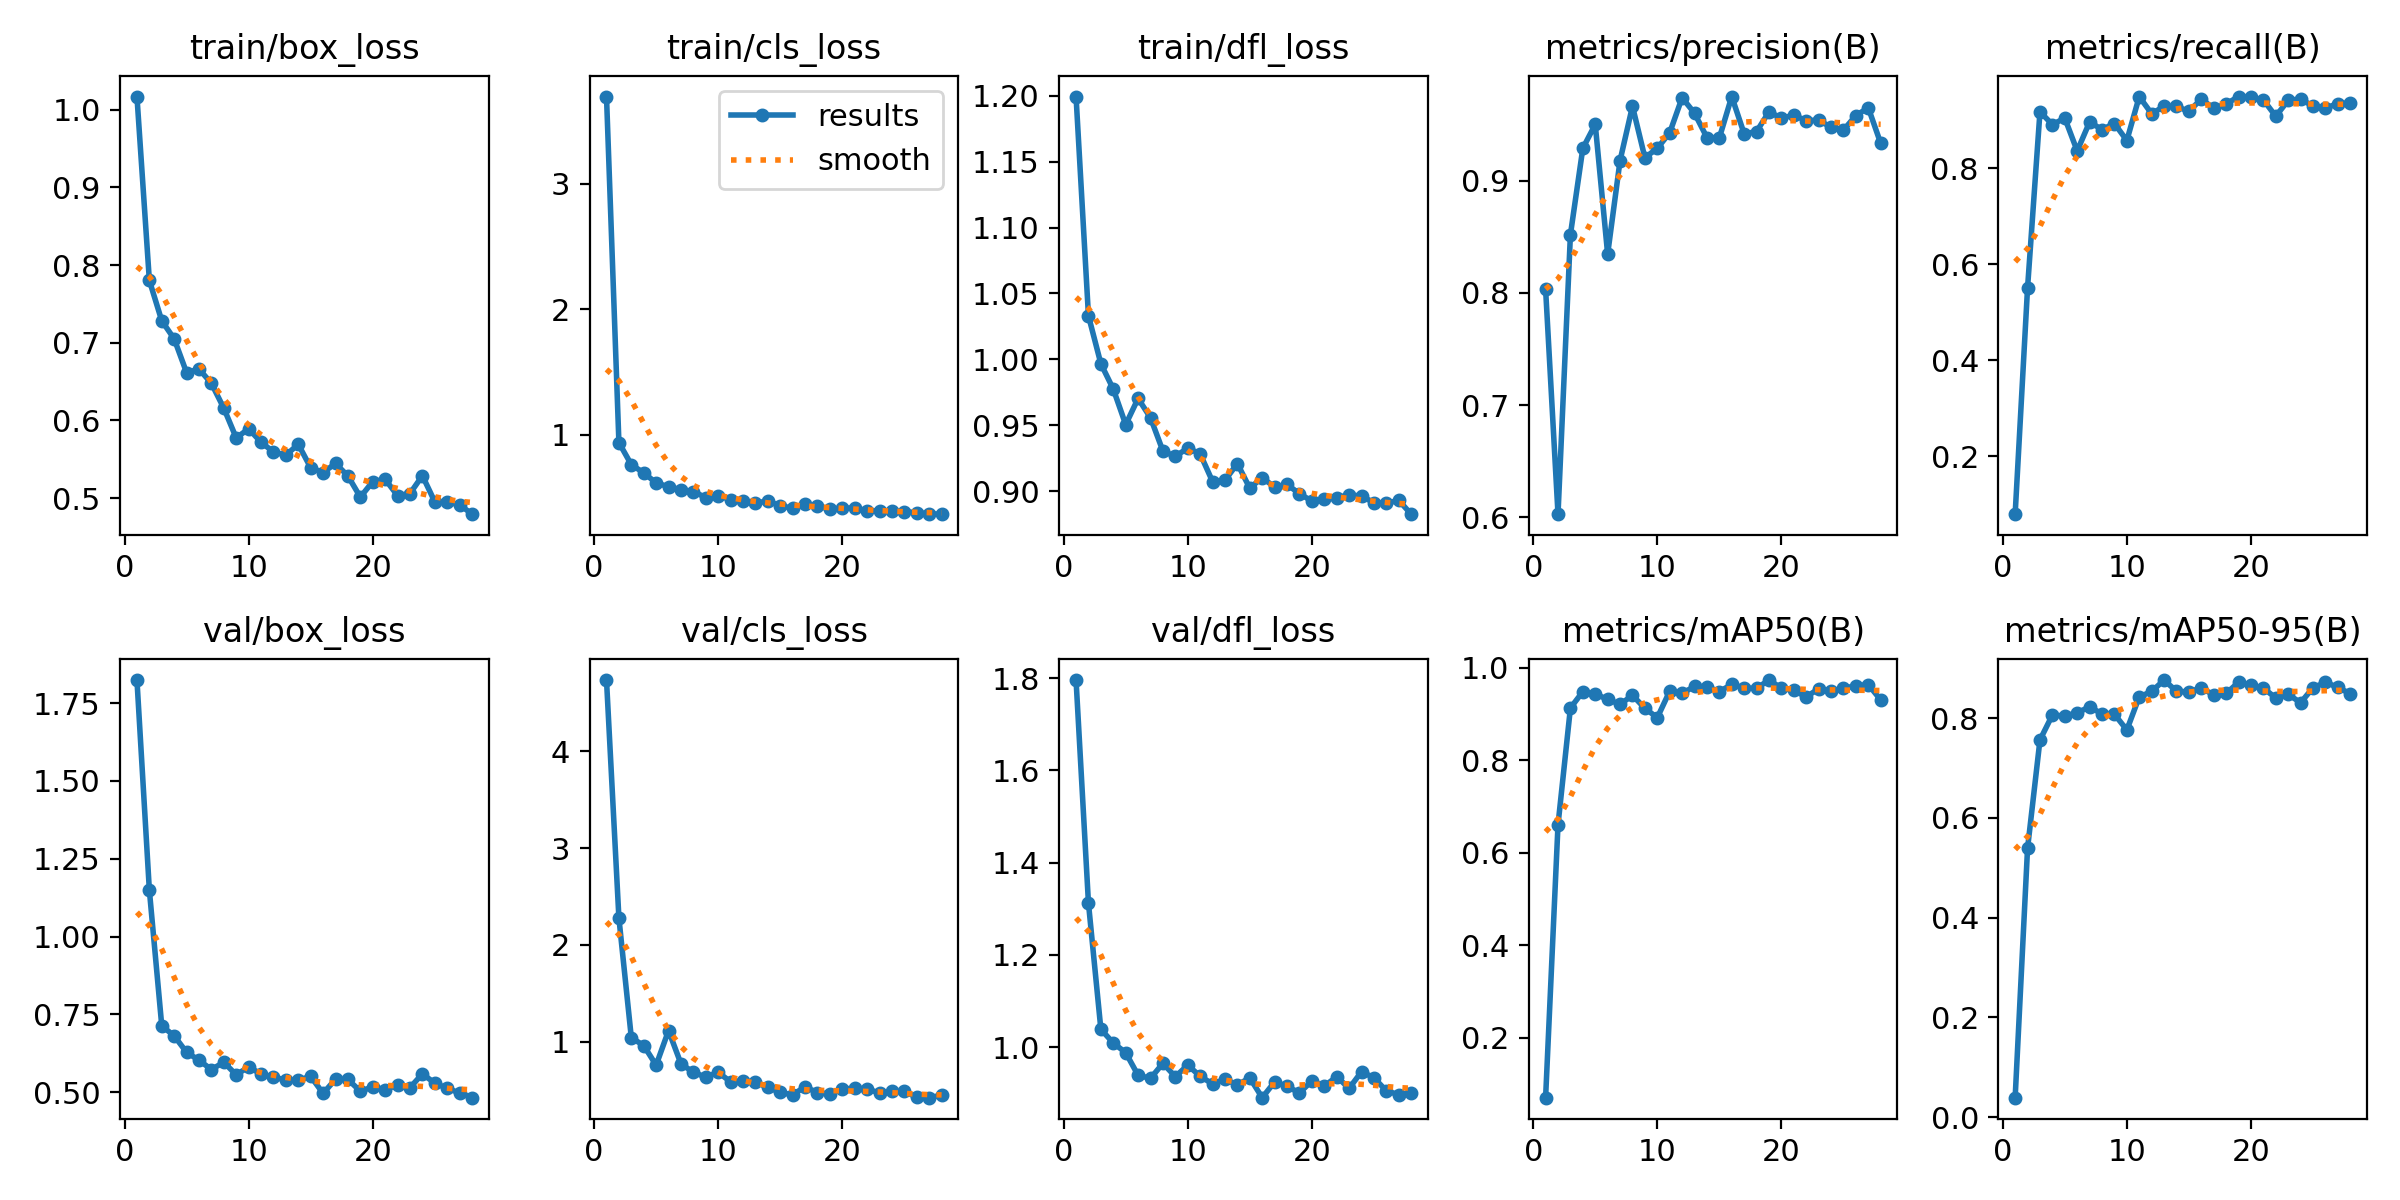

In [5]:
import os, glob
from IPython.display import Image, display
from ultralytics import YOLO

# Tải trọng số tốt nhất (best.pt) từ đúng thư mục runs/detect
best_model = YOLO('/content/runs/detect/phenikaa_flora_yolo/train_run/weights/best.pt')

# Đánh giá trên tập TEST
metrics = best_model.val(data='/content/dataset_yolo/data.yaml', split='test')

print('\n' + '='*40)
print('=== KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP TEST ===')
print(f'mAP@50:    {metrics.box.map50:.4f}')
print(f'mAP@50-95: {metrics.box.map:.4f}')
print(f'Precision: {metrics.box.mp:.4f}')
print(f'Recall:    {metrics.box.mr:.4f}')
print('='*40)

# Hiển thị Confusion Matrix
cm_path = '/content/runs/detect/phenikaa_flora_yolo/train_run/confusion_matrix_normalized.png'
if os.path.exists(cm_path):
    print('\nMa trận nhầm lẫn chuẩn hóa (Normalized Confusion Matrix):')
    display(Image(cm_path))

# Hiển thị đồ thị huấn luyện (Loss & mAP curves)
curves_path = '/content/runs/detect/phenikaa_flora_yolo/train_run/results.png'
if os.path.exists(curves_path):
    print('\nĐồ thị huấn luyện (Training & Validation Curves):')
    display(Image(curves_path))

## 🔍 Bước 4: Explainable AI (xAI) - Hiểu sâu cơ chế hoạt động của mô hình
Bao gồm 3 kỹ thuật cốt lõi:
1. **Activation Visualization (Feature Maps)**: Trực quan hóa các tầng nông $\rightarrow$ giữa $\rightarrow$ sâu.
2. **Grad-CAM++ / Eigen-CAM**: Bản đồ nhiệt chứng minh mô hình tập trung vào cánh hoa, nhụy hoa.
3. **t-SNE / PCA Feature Embedding**: Chiếu không gian đặc trưng của 10 loài hoa xuống 2D.

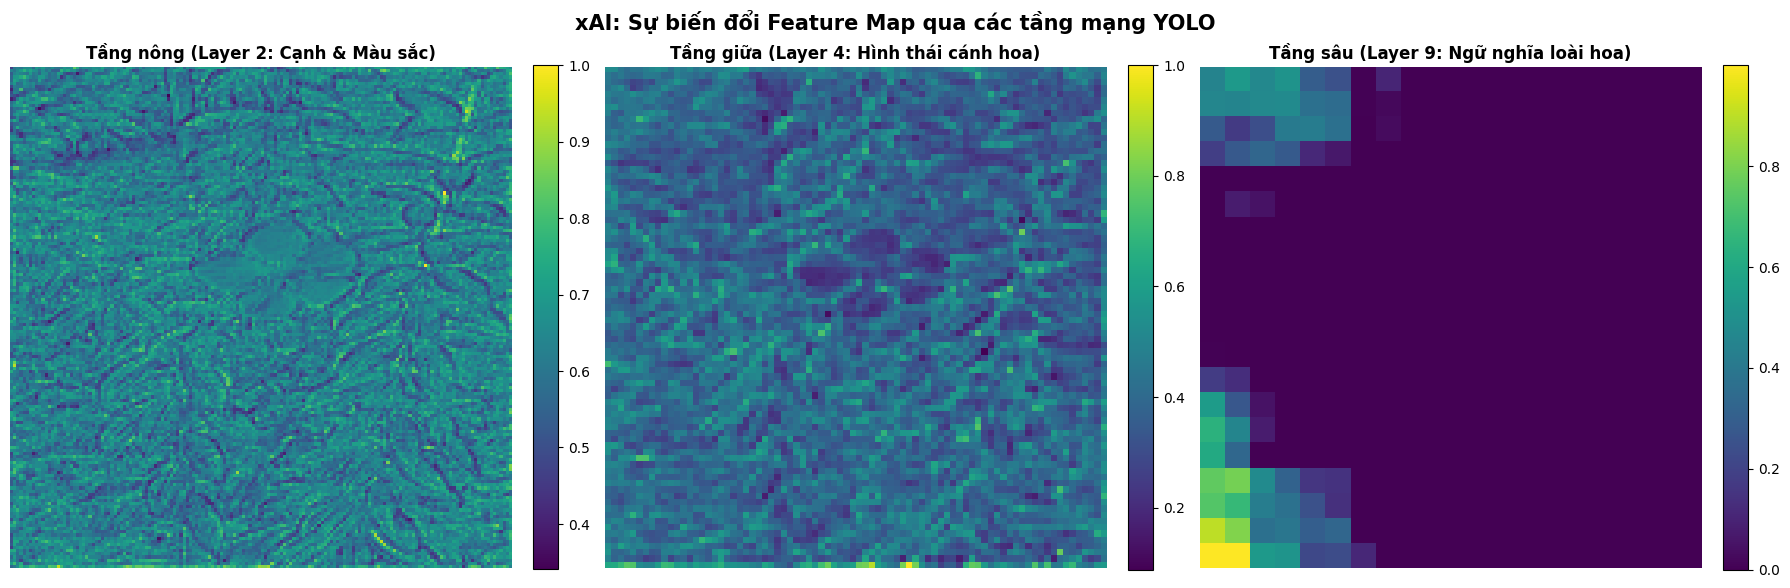

Saved /content/xai_results/feature_maps_activation.png


In [7]:
# 4.1. Feature Maps Activation Visualization across Layers
import torch, cv2
import numpy as np
import matplotlib.pyplot as plt

os.makedirs('/content/xai_results', exist_ok=True)

# Lấy 1 ảnh mẫu từ tập Test
test_imgs = glob.glob('/content/dataset_yolo/images/test/*.jpg')
sample_img_path = test_imgs[0]
orig_img = cv2.imread(sample_img_path)
orig_rgb = cv2.cvtColor(orig_img, cv2.COLOR_BGR2RGB)
img_resized = cv2.resize(orig_rgb, (640, 640))

# Xác định thiết bị tính toán (GPU nếu có, ngược lại dùng CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

tensor_in = torch.from_numpy(img_resized).permute(2, 0, 1).float().unsqueeze(0) / 255.0
tensor_in = tensor_in.to(device)

# Đăng ký forward hook để ghi nhận activation
activations = {}
def get_activation(name):
    def hook(model, input, output):
        activations[name] = output.detach()
    return hook

raw_model = best_model.model
# Đưa mô hình lên cùng thiết bị với input tensor
raw_model.to(device)

raw_model.model[2].register_forward_hook(get_activation('shallow_layer_2'))
raw_model.model[4].register_forward_hook(get_activation('intermediate_layer_4'))
raw_model.model[9].register_forward_hook(get_activation('deep_layer_9_sppf'))

with torch.no_grad():
    _ = raw_model(tensor_in)

# Vẽ biểu đồ 3 tầng đặc trưng
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
layers = ['shallow_layer_2', 'intermediate_layer_4', 'deep_layer_9_sppf']
titles = ['Tầng nông (Layer 2: Cạnh & Màu sắc)', 'Tầng giữa (Layer 4: Hình thái cánh hoa)', 'Tầng sâu (Layer 9: Ngữ nghĩa loài hoa)']

for ax, l_name, title in zip(axes, layers, titles):
    act = activations[l_name].squeeze(0).cpu().numpy()
    heatmap = np.mean(act, axis=0)
    heatmap = np.maximum(heatmap, 0)
    heatmap /= (np.max(heatmap) + 1e-8)
    im = ax.imshow(heatmap, cmap='viridis')
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.axis('off')
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.suptitle('xAI: Sự biến đổi Feature Map qua các tầng mạng YOLO', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig('/content/xai_results/feature_maps_activation.png', dpi=200)
plt.show()
print('Saved /content/xai_results/feature_maps_activation.png')

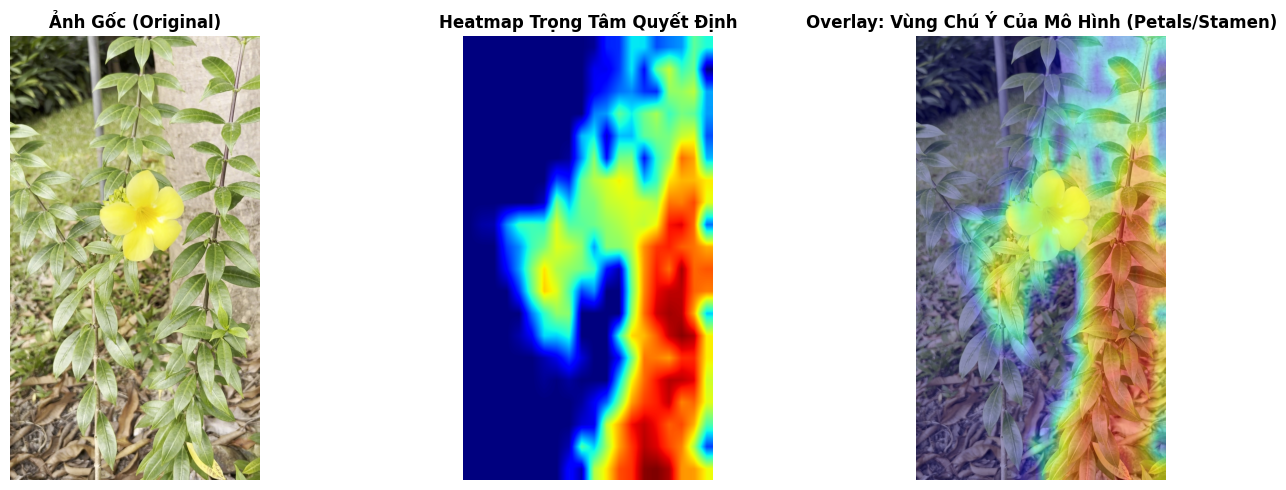

Saved /content/xai_results/gradcam_overlay.png


In [8]:
# 4.2. Eigen-CAM / Grad-CAM++ Heatmap Overlay
act_deep = activations['deep_layer_9_sppf'].squeeze(0).cpu().numpy()
C, H, W = act_deep.shape
reshaped = act_deep.reshape(C, H * W).T
reshaped = reshaped - np.mean(reshaped, axis=0)
U, S, Vt = np.linalg.svd(reshaped, full_matrices=False)
cam = U[:, 0].reshape(H, W)
cam = np.maximum(cam, 0)
cam = cv2.resize(cam, (orig_rgb.shape[1], orig_rgb.shape[0]))
cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

heatmap_color = cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET)
heatmap_color = cv2.cvtColor(heatmap_color, cv2.COLOR_BGR2RGB)
cam_blend = cv2.addWeighted(orig_rgb, 0.6, heatmap_color, 0.4, 0)

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(orig_rgb)
plt.title('Ảnh Gốc (Original)', fontsize=12, fontweight='bold')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(cam, cmap='jet')
plt.title('Heatmap Trọng Tâm Quyết Định', fontsize=12, fontweight='bold')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(cam_blend)
plt.title('Overlay: Vùng Chú Ý Của Mô Hình (Petals/Stamen)', fontsize=12, fontweight='bold')
plt.axis('off')

plt.tight_layout()
plt.savefig('/content/xai_results/gradcam_overlay.png', dpi=200)
plt.show()
print('Saved /content/xai_results/gradcam_overlay.png')

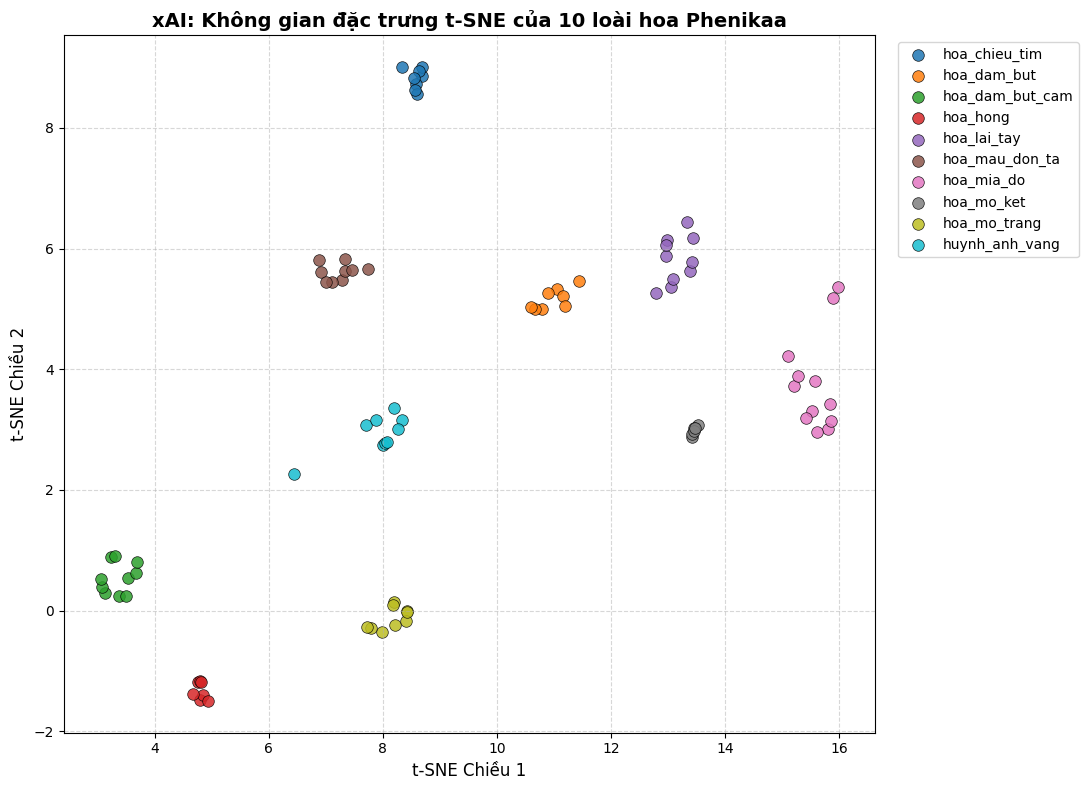

Saved /content/xai_results/tsne_embedding_space.png


In [9]:
# 4.3. t-SNE Feature Embedding Space (10 Loài Hoa)
from sklearn.manifold import TSNE
import seaborn as sns

class_names = [
    'hoa_chieu_tim', 'hoa_dam_but', 'hoa_dam_but_cam', 'hoa_hong',
    'hoa_lai_tay', 'hoa_mau_don_ta', 'hoa_mia_do', 'hoa_mo_ket',
    'hoa_mo_trang', 'huynh_anh_vang'
]

test_label_files = glob.glob('/content/dataset_yolo/labels/test/*.txt')
embeddings = []
labels = []

sppf_out = []
def hook_fn(m, i, o):
    pooled = torch.mean(o, dim=[2, 3]).squeeze(0)
    sppf_out.append(pooled.detach().cpu().numpy())

hook_handle = raw_model.model[9].register_forward_hook(hook_fn)

for lf in test_label_files:
    base = os.path.splitext(os.path.basename(lf))[0]
    img_path = os.path.join('/content/dataset_yolo/images/test', base + '.jpg')
    if not os.path.exists(img_path):
        continue
    with open(lf, 'r') as f:
        first_line = f.readline().strip()
        if not first_line:
            continue
        c_id = int(first_line.split()[0])

    img = cv2.imread(img_path)
    if img is None:
        continue
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img_r = cv2.resize(img_rgb, (640, 640))
    t = torch.from_numpy(img_r).permute(2, 0, 1).float().unsqueeze(0) / 255.0
    t = t.to('cuda' if torch.cuda.is_available() else 'cpu')

    sppf_out.clear()
    with torch.no_grad():
        _ = raw_model(t)

    if sppf_out:
        embeddings.append(sppf_out[0])
        labels.append(c_id)

hook_handle.remove()
embeddings = np.array(embeddings)
labels = np.array(labels)

tsne = TSNE(n_components=2, perplexity=min(25, len(embeddings)-1), random_state=42)
emb_2d = tsne.fit_transform(embeddings)

plt.figure(figsize=(11, 8))
palette = sns.color_palette('tab10', 10)

for c_id in range(10):
    mask = (labels == c_id)
    if np.any(mask):
        plt.scatter(emb_2d[mask, 0], emb_2d[mask, 1],
                    label=class_names[c_id], color=palette[c_id],
                    s=70, alpha=0.85, edgecolors='k', linewidth=0.5)

plt.title('xAI: Không gian đặc trưng t-SNE của 10 loài hoa Phenikaa', fontsize=14, fontweight='bold')
plt.xlabel('t-SNE Chiều 1', fontsize=12)
plt.ylabel('t-SNE Chiều 2', fontsize=12)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('/content/xai_results/tsne_embedding_space.png', dpi=200)
plt.show()
print('Saved /content/xai_results/tsne_embedding_space.png')

## 🌐 Bước 5: Xuất mô hình sang định dạng ONNX
Mô hình ONNX (`best.onnx`) sẽ được nạp trực tiếp vào trình duyệt (PC & Mobile) qua **ONNX Runtime Web** trên GitHub Pages mà không cần bất kỳ backend server nào.

In [10]:
# Export sang ONNX opset=12, imgsz=640
onnx_path = best_model.export(format='onnx', opset=12, simplify=True, imgsz=640)
print(f'Mô hình ONNX đã xuất thành công tại: {onnx_path}')

# Kiểm tra tính toàn vẹn của mô hình ONNX
import onnx
onnx_model = onnx.load(onnx_path)
onnx.checker.check_model(onnx_model)
print('✅ Mô hình ONNX hợp lệ 100%!')

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
Model summary (fused): 73 layers, 3,134,894 parameters, 0 gradients, 8.6 GFLOPs

PyTorch: starting from '/content/runs/detect/phenikaa_flora_yolo/train_run/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 14, 8400) (6.2 MB)
requirements: Ultralytics requirement ['onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 10 packages in 256ms
Prepared 2 packages in 27ms
Installed 2 packages in 5ms
 + colorama==0.4.6
 + onnxslim==0.1.98

requirements: AutoUpdate success ✅ 0.6s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.23.2 opset 12...
ONNX: slimming with onnxslim 0.1.98...
ONNX: export success ✅ 2.3s, saved as

## 📥 Bước 6: Đóng gói và Tải kết quả về máy
Tự động nén trọng số `best.pt`, `best.onnx`, các biểu đồ huấn luyện và kết quả xAI vào file zip để tải về máy phục vụ báo cáo và deploy web.

In [12]:
import shutil, glob, os
from google.colab import files

bundle_dir = '/content/Phenikaa_Flora_Results'
os.makedirs(bundle_dir, exist_ok=True)

# Sao chép weights từ đúng thư mục runs/detect
shutil.copy('/content/runs/detect/phenikaa_flora_yolo/train_run/weights/best.pt', f'{bundle_dir}/best.pt')
shutil.copy(onnx_path, f'{bundle_dir}/best.onnx')

# Sao chép các đồ thị huấn luyện & ma trận nhầm lẫn từ runs/detect
for f in glob.glob('/content/runs/detect/phenikaa_flora_yolo/train_run/*.png'):
    shutil.copy(f, bundle_dir)

# Sao chép kết quả xAI
for f in glob.glob('/content/xai_results/*.png'):
    shutil.copy(f, bundle_dir)

# Nén thành file zip
zip_output = '/content/Phenikaa_Flora_Trained_Results'
shutil.make_archive(zip_output, 'zip', bundle_dir)
print(f'Đã tạo gói kết quả: {zip_output}.zip')

# Tải về máy tự động
files.download(f'{zip_output}.zip')

Đã tạo gói kết quả: /content/Phenikaa_Flora_Trained_Results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>